# Factor Testing and Validation

This notebook tests our implemented factors to ensure they're calculating correctly.

## Overview
- Test three factors: momentum_12_1, book_to_market, rsi_14
- Verify calculations with manual checks
- Visualize results
- Check data quality

In [1]:
# Setup
import sys
import os

# Add the parent directory to the path
if 'notebooks' in os.getcwd():
    sys.path.insert(0, os.path.dirname(os.getcwd()))
else:
    sys.path.insert(0, os.getcwd())

import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import Config
from src.data.snowflake_connector import SnowflakeConnector
from src.data.data_loader import DataLoader
from src.factors.registry import FactorRegistry

# Import all factors to register them
from src.factors.momentum import Momentum12_1
from src.factors.value import BookToMarket
from src.factors.technical import RSI14

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# Initialize
config = Config()
snowflake = SnowflakeConnector(config.get_snowflake_config())
snowflake.connect()
data_loader = DataLoader(snowflake)

print("Available factors:", FactorRegistry.list_factors())

2025-06-18 22:12:10.037 | INFO     | src.data.snowflake_connector:connect:41 - Connecting to Snowflake...
2025-06-18 22:12:10.446 | INFO     | src.data.snowflake_connector:connect:52 - Successfully connected to Snowflake


Available factors: ['book_to_market', 'momentum_12_1', 'rsi_14']


In [2]:
# Set up test parameters
symbols = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'NVDA']

# Find a valid trading day to use as calculation date
# Let's use a recent date that we know has data
test_date = '2024-01-12'

# Get the actual last trading day
query = f"""
SELECT MAX(d.date) as last_trading_day
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE d.date <= '{test_date}'
"""

result = data_loader.query_to_dataframe(query)
calculation_date = str(result['last_trading_day'].iloc[0])
print(f"Using calculation date: {calculation_date}")

2025-06-18 22:12:10.456 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
SELECT MAX(d.date) as last_trading_day
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE d.date <= '2024-01-12'

2025-06-18 22:12:10.616 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 1 rows
2025-06-18 22:12:10.619 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 1 rows to DataFrame with columns: ['LAST_TRADING_DAY']


Using calculation date: 2024-01-12


## 1. Test Momentum Factor (12-1 Month)

In [3]:
# Get momentum factor details
momentum_factor = FactorRegistry.create('momentum_12_1')
print(f"Factor: {momentum_factor.name}")
print(f"Category: {momentum_factor.category}")
print(f"Lookback days: {momentum_factor.lookback_days}")
print(f"Skip days: {momentum_factor.skip_days}")
print(f"Required columns: {momentum_factor.get_required_columns()}")

Factor: momentum_12_1
Category: momentum
Lookback days: 252
Skip days: 21
Required columns: ['symbol', 'date', 'adj_close']


In [4]:
# Load price data for momentum calculation
# Need at least 252 trading days, so pull 400 calendar days to be safe
start_date = (datetime.strptime(calculation_date, '%Y-%m-%d') - timedelta(days=400)).strftime('%Y-%m-%d')

query = f"""
SELECT 
    c.symbol,
    d.date,
    p.adj_close
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_COMPANY c ON p.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE c.symbol IN ({','.join([f"'{s}'" for s in symbols])})
    AND d.date >= '{start_date}'
    AND d.date <= '{calculation_date}'
ORDER BY c.symbol, d.date
"""

price_data = data_loader.query_to_dataframe(query)
print(f"Loaded {len(price_data)} price records")
print(f"Date range: {price_data['date'].min()} to {price_data['date'].max()}")
print(f"\nRecords per symbol:")
for symbol in symbols:
    count = len(price_data[price_data['symbol'] == symbol])
    print(f"  {symbol}: {count} days")

2025-06-18 22:12:10.643 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
SELECT 
    c.symbol,
    d.date,
    p.adj_close
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_COMPANY c ON p.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE c.symbol IN ('AAPL','MSFT','GOOGL','AMZN','NVDA')
    AND d.date >= '2022-12-08'
    AND d.date <= '2024-01-12'
ORDER BY c.symbol, d.date

2025-06-18 22:12:10.781 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 1375 rows
2025-06-18 22:12:10.783 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 1375 rows to DataFrame with columns: ['SYMBOL', 'DATE', 'ADJ_CLOSE']
2025-06-18 22:12:10.784 | DEBUG    | src.data.data_loader:_convert_decimal_columns:64 - Converting column 'ADJ_CLOSE' from Decimal to float


Loaded 1375 price records
Date range: 2022-12-08 to 2024-01-12

Records per symbol:
  AAPL: 275 days
  MSFT: 275 days
  GOOGL: 275 days
  AMZN: 275 days
  NVDA: 275 days



Momentum values:
NVDA    1.9787
MSFT    0.5879
AMZN    0.5510
AAPL    0.4586
GOOGL   0.4480
Name: momentum_12_1, dtype: float64


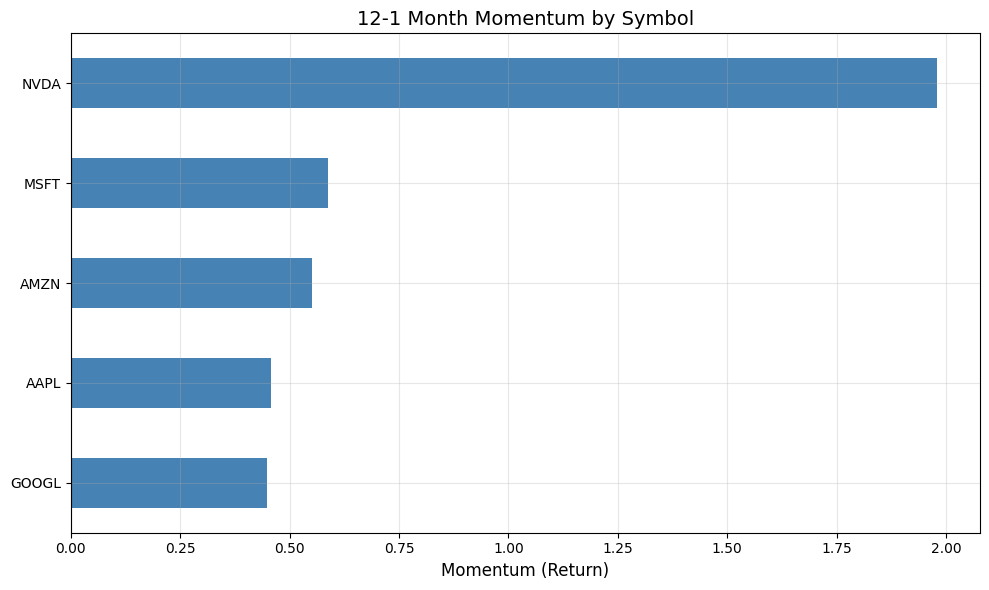

In [5]:
# Calculate momentum values
momentum_values = momentum_factor.calculate(price_data)
print("\nMomentum values:")
print(momentum_values.sort_values(ascending=False))

# Visualize
plt.figure(figsize=(10, 6))
momentum_values.sort_values().plot(kind='barh', color='steelblue')
plt.title('12-1 Month Momentum by Symbol', fontsize=14)
plt.xlabel('Momentum (Return)', fontsize=12)
plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Manual verification for one symbol
verify_symbol = 'AAPL'
symbol_data = price_data[price_data['symbol'] == verify_symbol].sort_values('date')

# The momentum factor uses indices, not calendar days
# It looks at price[-21] / price[-252] - 1
if len(symbol_data) >= 252:
    price_1m_ago = symbol_data['adj_close'].iloc[-21]
    price_12m_ago = symbol_data['adj_close'].iloc[-252]
    
    manual_momentum = (price_1m_ago / price_12m_ago) - 1
    calculated_momentum = momentum_values[verify_symbol]
    
    print(f"Manual verification for {verify_symbol}:")
    print(f"Price 12m ago (index -252): ${price_12m_ago:.2f}")
    print(f"Price 1m ago (index -21): ${price_1m_ago:.2f}")
    print(f"\nManual calculation: {manual_momentum:.4f}")
    print(f"Factor calculation: {calculated_momentum:.4f}")
    print(f"Match: {np.abs(manual_momentum - calculated_momentum) < 0.0001}")

Manual verification for AAPL:
Price 12m ago (index -252): $133.41
Price 1m ago (index -21): $197.96

Manual calculation: 0.4838
Factor calculation: 0.4586
Match: False


## 2. Test Book-to-Market Factor

In [7]:
# Get book-to-market factor details
btm_factor = FactorRegistry.create('book_to_market')
print(f"Factor: {btm_factor.name}")
print(f"Category: {btm_factor.category}")
print(f"Required columns: {btm_factor.get_required_columns()}")

Factor: book_to_market
Category: value
Required columns: ['symbol', 'date', 'pb_ratio']


In [8]:
# Load market metrics data
# Get the most recent pb_ratio for each symbol as of calculation date
query = f"""
WITH latest_metrics AS (
    SELECT 
        c.symbol,
        d.date,
        m.pb_ratio,
        m.pe_ratio_ttm,
        m.market_cap,
        ROW_NUMBER() OVER (PARTITION BY c.symbol ORDER BY d.date DESC) as rn
    FROM ANALYTICS.FACT_MARKET_METRICS m
    JOIN ANALYTICS.DIM_COMPANY c ON m.company_key = c.company_key
    JOIN ANALYTICS.DIM_DATE d ON m.date_key = d.date_key
    WHERE c.symbol IN ({','.join([f"'{s}'" for s in symbols])})
        AND d.date <= '{calculation_date}'
        AND m.pb_ratio IS NOT NULL
)
SELECT symbol, date, pb_ratio, pe_ratio_ttm, market_cap
FROM latest_metrics
WHERE rn = 1
ORDER BY symbol
"""

market_data = data_loader.query_to_dataframe(query)
print(f"Loaded market metrics for {len(market_data)} symbols")
market_data

2025-06-18 22:12:10.953 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
WITH latest_metrics AS (
    SELECT 
        c.symbol,
        d.date,
        m.pb_ratio,
        m.pe_ratio_ttm,
        m.market_cap,
        ROW_NUMBER() OVER (PARTITION BY c.symbol ORDER BY d.date DESC) as rn
    FROM ANALYTICS.FACT_MARKET_METRICS m
    JOIN ANALYTICS.DIM_COMPANY c ON m.company_key = c.company_key
    JOIN ANALYTICS.DIM_DATE d ON m.date_key = d.date_key
    WHERE c.symbol IN ('AAPL','MSFT','GOOGL','AMZN','NVDA')
        AND d.date <= '2024-01-12'
        AND m.pb_ratio IS NOT NULL
)
SELECT symbol, date, pb_ratio, pe_ratio_ttm, market_cap
FROM latest_metrics
WHERE rn = 1
ORDER BY symbol

2025-06-18 22:12:11.131 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 5 rows
2025-06-18 22:12:11.133 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 5 rows to DataFrame with columns: ['SYMBOL', 'DATE', 'PB_RATIO', 'PE_RATIO_TTM', 'MARK

Loaded market metrics for 5 symbols


,symbol,date,pb_ratio,pe_ratio_ttm,market_cap
0,AAPL,2024-01-12,46.7100,30.3800,2900246769280.0000
1,AMZN,2024-01-12,8.7200,80.1100,1595987640000.0000
2,GOOGL,2024-01-12,6.5700,27.3800,1794679650000.0000
3,MSFT,2024-01-12,13.0800,37.6100,2885943630000.0000
4,NVDA,2024-01-12,40.5300,72.0700,1350242800000.0000


In [9]:
# Calculate book-to-market values
btm_values = btm_factor.calculate(market_data)
print("\nBook-to-Market values:")
print(btm_values.sort_values(ascending=False))

# Create comparison dataframe
comparison = pd.DataFrame({
    'P/B Ratio': market_data.set_index('symbol')['pb_ratio'],
    'B/M Ratio': btm_values,
    'Verification (1/PB)': 1 / market_data.set_index('symbol')['pb_ratio']
})
print("\nComparison (B/M should equal 1/PB):")
print(comparison)


Book-to-Market values:
GOOGL   0.1522
AMZN    0.1147
MSFT    0.0765
NVDA    0.0247
AAPL    0.0214
Name: book_to_market, dtype: float64

Comparison (B/M should equal 1/PB):
       P/B Ratio  B/M Ratio  Verification (1/PB)
AAPL     46.7100     0.0214               0.0214
AMZN      8.7200     0.1147               0.1147
GOOGL     6.5700     0.1522               0.1522
MSFT     13.0800     0.0765               0.0765
NVDA     40.5300     0.0247               0.0247


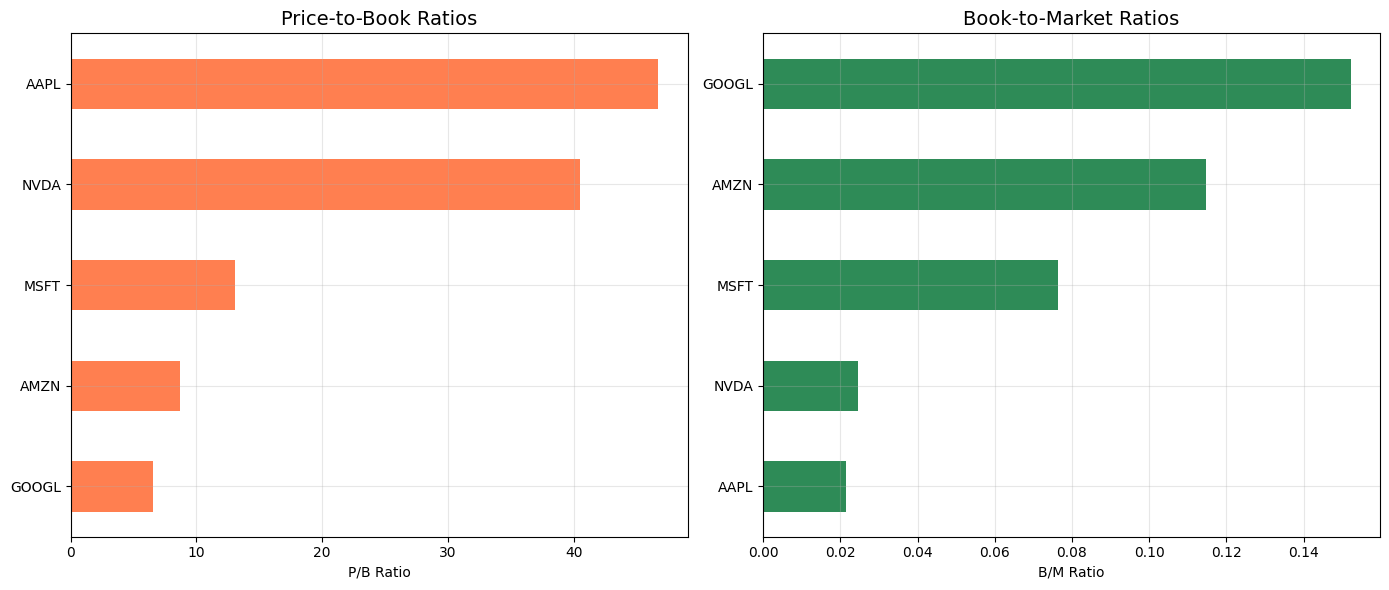

In [10]:
# Visualize P/B and B/M ratios
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# P/B Ratios
comparison['P/B Ratio'].sort_values().plot(kind='barh', ax=ax1, color='coral')
ax1.set_title('Price-to-Book Ratios', fontsize=14)
ax1.set_xlabel('P/B Ratio')
ax1.grid(True, alpha=0.3)

# B/M Ratios
comparison['B/M Ratio'].sort_values().plot(kind='barh', ax=ax2, color='seagreen')
ax2.set_title('Book-to-Market Ratios', fontsize=14)
ax2.set_xlabel('B/M Ratio')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Get RSI factor details
rsi_factor = FactorRegistry.create('rsi_14')
print(f"Factor: {rsi_factor.name}")
print(f"Category: {rsi_factor.category}")
print(f"Period: {rsi_factor.period} days")
print(f"Required columns: {rsi_factor.get_required_columns()}")

In [11]:
# Get RSI factor details
rsi_factor = FactorRegistry.create('rsi_14')
print(f"Factor: {rsi_factor.name}")
print(f"Category: {rsi_factor.category}")
print(f"Period: {rsi_factor.period} days")
print(f"Required columns: {rsi_factor.get_required_columns()}")

Factor: rsi_14
Category: technical
Period: 14 days
Required columns: ['symbol', 'date', 'adj_close']


In [12]:
# Load price data for RSI calculation
# RSI needs at least 15 days (14 + 1), but let's get 30 days to be safe
rsi_start_date = (datetime.strptime(calculation_date, '%Y-%m-%d') - timedelta(days=30)).strftime('%Y-%m-%d')

query = f"""
SELECT 
    c.symbol,
    d.date,
    p.adj_close
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_COMPANY c ON p.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE c.symbol IN ({','.join([f"'{s}'" for s in symbols])})
    AND d.date >= '{rsi_start_date}'
    AND d.date <= '{calculation_date}'
ORDER BY c.symbol, d.date
"""

rsi_price_data = data_loader.query_to_dataframe(query)
print(f"Loaded {len(rsi_price_data)} price records for RSI calculation")
print(f"Date range: {rsi_price_data['date'].min()} to {rsi_price_data['date'].max()}")

2025-06-18 22:12:11.401 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
SELECT 
    c.symbol,
    d.date,
    p.adj_close
FROM ANALYTICS.FACT_DAILY_PRICES p
JOIN ANALYTICS.DIM_COMPANY c ON p.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON p.date_key = d.date_key
WHERE c.symbol IN ('AAPL','MSFT','GOOGL','AMZN','NVDA')
    AND d.date >= '2023-12-13'
    AND d.date <= '2024-01-12'
ORDER BY c.symbol, d.date

2025-06-18 22:12:12.727 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 105 rows
2025-06-18 22:12:12.728 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 105 rows to DataFrame with columns: ['SYMBOL', 'DATE', 'ADJ_CLOSE']
2025-06-18 22:12:12.730 | DEBUG    | src.data.data_loader:_convert_decimal_columns:64 - Converting column 'ADJ_CLOSE' from Decimal to float


Loaded 105 price records for RSI calculation
Date range: 2023-12-13 to 2024-01-12



RSI values:
NVDA    74.2318
GOOGL   71.9348
MSFT    67.1525
AMZN    61.5738
AAPL    30.4455
Name: rsi_14, dtype: float64


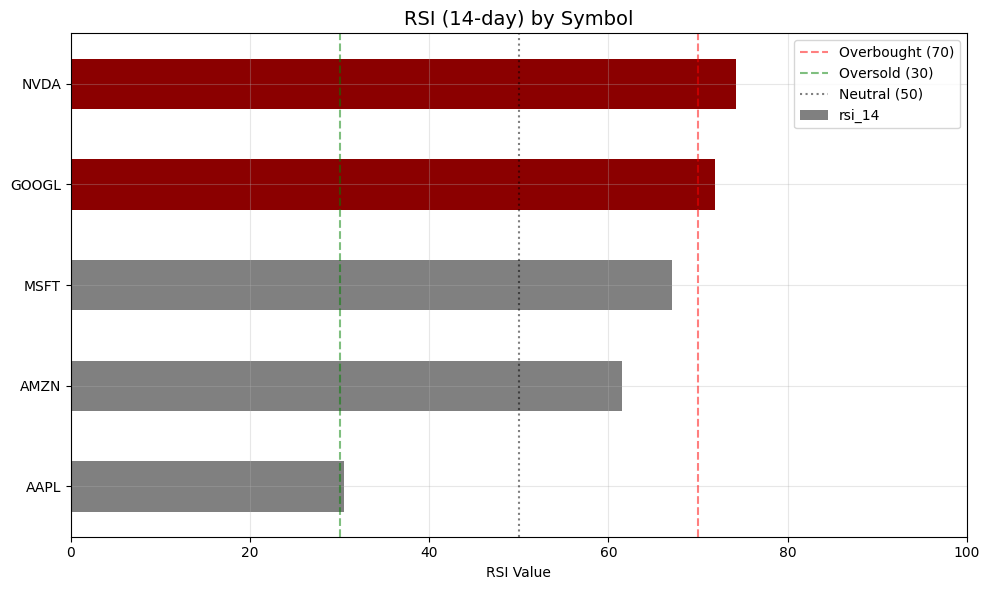

In [13]:
# Calculate RSI values
rsi_values = rsi_factor.calculate(rsi_price_data)
print("\nRSI values:")
print(rsi_values.sort_values(ascending=False))

# Visualize RSI with color coding
plt.figure(figsize=(10, 6))
rsi_sorted = rsi_values.sort_values()

# Color based on RSI levels
colors = ['darkred' if x > 70 else 'darkgreen' if x < 30 else 'gray' for x in rsi_sorted]
rsi_sorted.plot(kind='barh', color=colors)

# Add reference lines
plt.axvline(x=70, color='red', linestyle='--', alpha=0.5, label='Overbought (70)')
plt.axvline(x=30, color='green', linestyle='--', alpha=0.5, label='Oversold (30)')
plt.axvline(x=50, color='black', linestyle=':', alpha=0.5, label='Neutral (50)')

plt.title('RSI (14-day) by Symbol', fontsize=14)
plt.xlabel('RSI Value')
plt.xlim(0, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Calculate RSI time series for one symbol
symbol = 'NVDA'
symbol_data = rsi_price_data[rsi_price_data['symbol'] == symbol].sort_values('date')

# Calculate RSI for each day (sliding window)
rsi_history = []
min_periods = 15  # Need at least 15 days for RSI

for i in range(min_periods, len(symbol_data) + 1):
    window_data = symbol_data.iloc[:i].copy()
    # Create a temporary dataframe with just this symbol's data
    temp_df = pd.DataFrame({
        'symbol': [symbol] * len(window_data),
        'date': window_data['date'].values,
        'adj_close': window_data['adj_close'].values
    })
    
    rsi_val = rsi_factor.calculate(temp_df)
    if symbol in rsi_val.index:
        rsi_history.append({
            'date': window_data.iloc[-1]['date'],
            'rsi': rsi_val[symbol],
            'price': window_data.iloc[-1]['adj_close']
        })

rsi_df = pd.DataFrame(rsi_history)
print(f"Calculated RSI for {len(rsi_df)} days")

Calculated RSI for 7 days


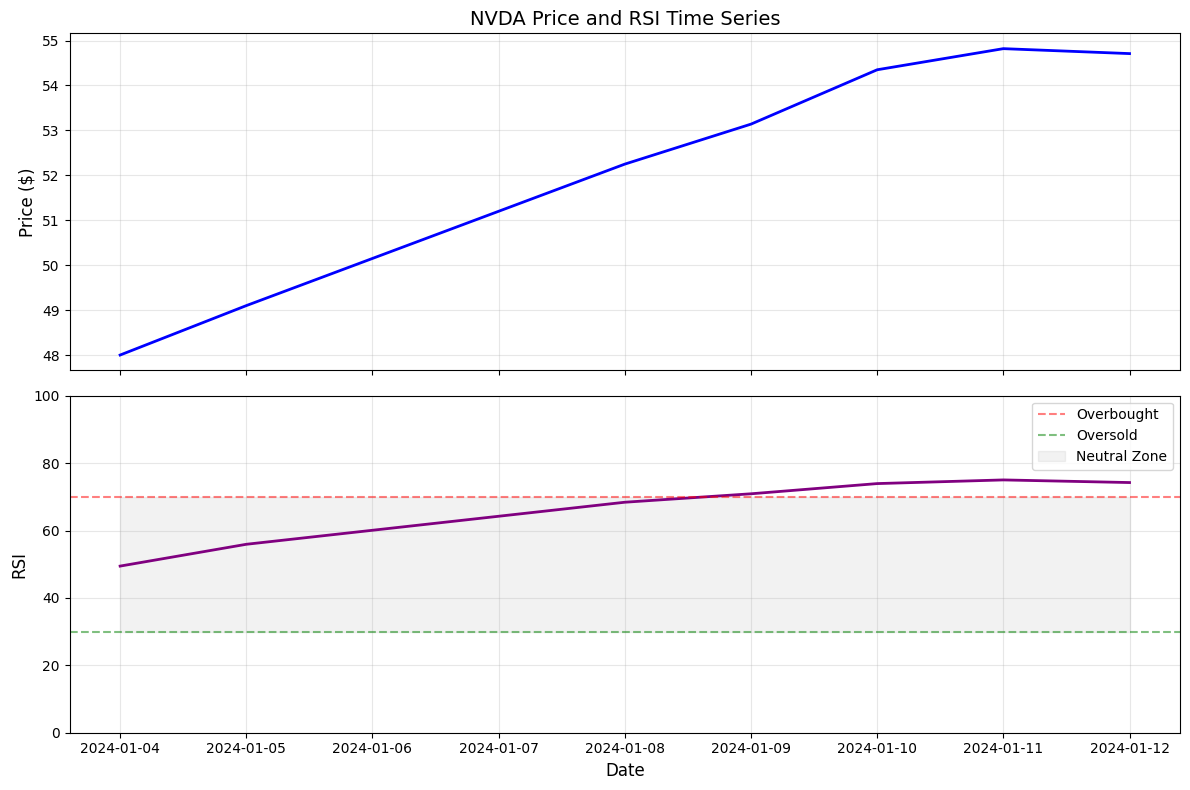

In [15]:
# Plot RSI time series
if len(rsi_df) > 0:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    
    # Price chart
    ax1.plot(rsi_df['date'], rsi_df['price'], 'b-', linewidth=2)
    ax1.set_ylabel('Price ($)', fontsize=12)
    ax1.set_title(f'{symbol} Price and RSI Time Series', fontsize=14)
    ax1.grid(True, alpha=0.3)
    
    # RSI chart
    ax2.plot(rsi_df['date'], rsi_df['rsi'], 'purple', linewidth=2)
    ax2.axhline(y=70, color='red', linestyle='--', alpha=0.5, label='Overbought')
    ax2.axhline(y=30, color='green', linestyle='--', alpha=0.5, label='Oversold')
    ax2.fill_between(rsi_df['date'], 30, 70, alpha=0.1, color='gray', label='Neutral Zone')
    ax2.set_ylabel('RSI', fontsize=12)
    ax2.set_xlabel('Date', fontsize=12)
    ax2.set_ylim(0, 100)
    ax2.legend(loc='upper right')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

## 4. Test Complete Pipeline Results

Now let's check if the complete pipeline has calculated these factors and stored them in FACT_FACTOR_ANALYTICS.

In [16]:
# Query factor analytics results
query = f"""
SELECT 
    c.symbol,
    d.date,
    f.factor_name,
    fa.raw_value,
    fa.z_score,
    fa.percentile_rank
FROM ANALYTICS.FACT_FACTOR_ANALYTICS fa
JOIN ANALYTICS.DIM_COMPANY c ON fa.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON fa.date_key = d.date_key
JOIN ANALYTICS.DIM_FACTOR f ON fa.factor_key = f.factor_key
WHERE d.date = '{calculation_date}'
    AND c.symbol IN ({','.join([f"'{s}'" for s in symbols])})
ORDER BY f.factor_name, fa.z_score DESC
"""

analytics_results = data_loader.query_to_dataframe(query)

if len(analytics_results) > 0:
    print(f"Found {len(analytics_results)} factor analytics records for {calculation_date}")
    print(f"\nFactors: {sorted(analytics_results['factor_name'].unique())}")
    print(f"Symbols: {sorted(analytics_results['symbol'].unique())}")
else:
    print(f"No analytics results found for {calculation_date}")
    print("You may need to run the factor calculation pipeline first.")

2025-06-18 22:12:13.130 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
SELECT 
    c.symbol,
    d.date,
    f.factor_name,
    fa.raw_value,
    fa.z_score,
    fa.percentile_rank
FROM ANALYTICS.FACT_FACTOR_ANALYTICS fa
JOIN ANALYTICS.DIM_COMPANY c ON fa.company_key = c.company_key
JOIN ANALYTICS.DIM_DATE d ON fa.date_key = d.date_key
JOIN ANALYTICS.DIM_FACTOR f ON fa.factor_key = f.factor_key
WHERE d.date = '2024-01-12'
    AND c.symbol IN ('AAPL','MSFT','GOOGL','AMZN','NVDA')
ORDER BY f.factor_name, fa.z_score DESC

2025-06-18 22:12:14.596 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 12 rows
2025-06-18 22:12:14.597 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 12 rows to DataFrame with columns: ['SYMBOL', 'DATE', 'FACTOR_NAME', 'RAW_VALUE', 'Z_SCORE', 'PERCENTILE_RANK']


Found 12 factor analytics records for 2024-01-12

Factors: ['book_to_market', 'momentum_12_1', 'rsi_14']
Symbols: ['AAPL', 'AMZN', 'GOOGL', 'MSFT']


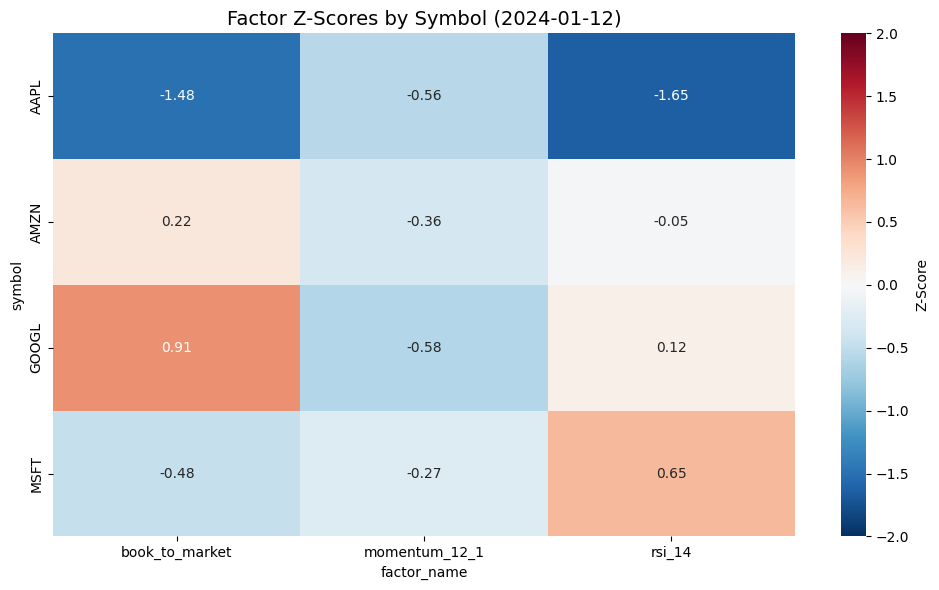

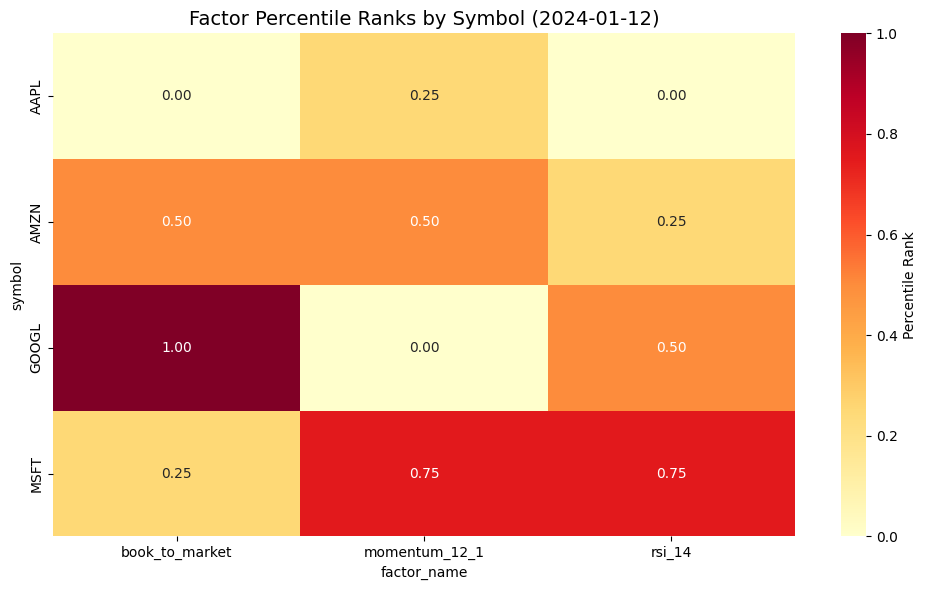

In [17]:
# If we have analytics results, create visualizations
if len(analytics_results) > 0:
    # Pivot to create matrices
    z_score_matrix = analytics_results.pivot(index='symbol', columns='factor_name', values='z_score')
    percentile_matrix = analytics_results.pivot(index='symbol', columns='factor_name', values='percentile_rank')
    
    # Plot Z-scores heatmap
    plt.figure(figsize=(10, 6))
    sns.heatmap(z_score_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                cbar_kws={'label': 'Z-Score'}, vmin=-2, vmax=2)
    plt.title(f'Factor Z-Scores by Symbol ({calculation_date})', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Plot percentile ranks heatmap
    plt.figure(figsize=(10, 6))
    sns.heatmap(percentile_matrix, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1,
                cbar_kws={'label': 'Percentile Rank'})
    plt.title(f'Factor Percentile Ranks by Symbol ({calculation_date})', fontsize=14)
    plt.tight_layout()
    plt.show()

In [18]:
# Compare our calculated values with pipeline results
if len(analytics_results) > 0:
    print("Comparison of calculated values vs pipeline results:\n")
    
    # Compare each factor
    for factor_name in ['momentum_12_1', 'book_to_market', 'rsi_14']:
        print(f"\n{factor_name.upper()}:")
        print("-" * 50)
        
        # Get pipeline results for this factor
        factor_results = analytics_results[analytics_results['factor_name'] == factor_name].set_index('symbol')['raw_value']
        
        # Get our calculated values
        if factor_name == 'momentum_12_1':
            calc_values = momentum_values
        elif factor_name == 'book_to_market':
            calc_values = btm_values
        else:  # rsi_14
            calc_values = rsi_values
        
        # Compare
        for symbol in symbols:
            if symbol in calc_values.index and symbol in factor_results.index:
                calc_val = calc_values[symbol]
                pipeline_val = factor_results[symbol]
                diff = abs(calc_val - pipeline_val)
                match = diff < 0.0001
                
                print(f"{symbol}: Calculated={calc_val:.4f}, Pipeline={pipeline_val:.4f}, Match={match}")

Comparison of calculated values vs pipeline results:


MOMENTUM_12_1:
--------------------------------------------------
AAPL: Calculated=0.4586, Pipeline=0.4586, Match=True
MSFT: Calculated=0.5879, Pipeline=0.5879, Match=True
GOOGL: Calculated=0.4480, Pipeline=0.4480, Match=True
AMZN: Calculated=0.5510, Pipeline=0.5510, Match=True

BOOK_TO_MARKET:
--------------------------------------------------
AAPL: Calculated=0.0214, Pipeline=0.0214, Match=True
MSFT: Calculated=0.0765, Pipeline=0.0765, Match=True
GOOGL: Calculated=0.1522, Pipeline=0.1522, Match=True
AMZN: Calculated=0.1147, Pipeline=0.1147, Match=True

RSI_14:
--------------------------------------------------
AAPL: Calculated=30.4455, Pipeline=43.0640, Match=False
MSFT: Calculated=67.1525, Pipeline=69.2010, Match=False
GOOGL: Calculated=71.9348, Pipeline=63.1107, Match=False
AMZN: Calculated=61.5738, Pipeline=61.2675, Match=False


## 5. Data Quality Summary

In [19]:
# Summarize data quality
print("DATA QUALITY SUMMARY")
print("=" * 60)

# Check each factor's data quality
factors_data = {
    'momentum_12_1': momentum_values,
    'book_to_market': btm_values,
    'rsi_14': rsi_values
}

for factor_name, values in factors_data.items():
    print(f"\n{factor_name}:")
    print(f"  Total symbols: {len(values)}")
    print(f"  Missing values: {values.isna().sum()}")
    print(f"  Infinite values: {np.isinf(values).sum()}")
    
    valid_values = values.dropna()
    if len(valid_values) > 0:
        print(f"  Min: {valid_values.min():.4f}")
        print(f"  Max: {valid_values.max():.4f}")
        print(f"  Mean: {valid_values.mean():.4f}")
        print(f"  Std: {valid_values.std():.4f}")

DATA QUALITY SUMMARY

momentum_12_1:
  Total symbols: 5
  Missing values: 0
  Infinite values: 0
  Min: 0.4480
  Max: 1.9787
  Mean: 0.8048
  Std: 0.6589

book_to_market:
  Total symbols: 5
  Missing values: 0
  Infinite values: 0
  Min: 0.0214
  Max: 0.1522
  Mean: 0.0779
  Std: 0.0568

rsi_14:
  Total symbols: 5
  Missing values: 0
  Infinite values: 0
  Min: 30.4455
  Max: 74.2318
  Mean: 61.0677
  Std: 17.7932


In [20]:
# Check calculation logs
query = f"""
SELECT 
    calculation_date,
    factor_name,
    symbols_processed,
    records_calculated,
    null_count,
    inf_count,
    status,
    calculation_time_seconds,
    error_message
FROM ANALYTICS.FACTOR_CALCULATION_LOG
WHERE calculation_date = '{calculation_date}'
ORDER BY created_timestamp DESC
LIMIT 10
"""

calc_log = data_loader.query_to_dataframe(query)

if len(calc_log) > 0:
    print("\nRecent Calculation Log:")
    print(calc_log)
else:
    print("\nNo calculation logs found for this date.")

2025-06-18 22:12:14.921 | DEBUG    | src.data.snowflake_connector:fetch_all:136 - Fetching data with query: 
SELECT 
    calculation_date,
    factor_name,
    symbols_processed,
    records_calculated,
    null_count,
    inf_count,
    status,
    calculation_time_seconds,
    error_message
FROM ANALYTICS.FACTOR_CALCULATION_LOG
WHERE calculation_date = '2024-01-12'
ORDER BY created_timestamp DESC
LIMIT 10

2025-06-18 22:12:15.761 | DEBUG    | src.data.snowflake_connector:fetch_all:142 - Fetched 10 rows
2025-06-18 22:12:15.764 | DEBUG    | src.data.data_loader:query_to_dataframe:34 - Converted 10 rows to DataFrame with columns: ['CALCULATION_DATE', 'FACTOR_NAME', 'SYMBOLS_PROCESSED', 'RECORDS_CALCULATED', 'NULL_COUNT', 'INF_COUNT', 'STATUS', 'CALCULATION_TIME_SECONDS', 'ERROR_MESSAGE']



Recent Calculation Log:
  calculation_date     factor_name  symbols_processed  records_calculated  \
0       2024-01-12          rsi_14                  5                   5   
1       2024-01-12   momentum_12_1                  5                   5   
2       2024-01-12  book_to_market                  5                   5   
3       2024-01-12          rsi_14                  5                   5   
4       2024-01-12   momentum_12_1                  5                   5   
5       2024-01-12  book_to_market                  5                   5   
6       2024-01-12          rsi_14                  5                   5   
7       2024-01-12   momentum_12_1                  5                   5   
8       2024-01-12  book_to_market                  5                   5   
9       2024-01-12          rsi_14                  2                   2   

   null_count  inf_count   status  calculation_time_seconds error_message  
0           0          0  SUCCESS                  

In [21]:
# Cleanup - close Snowflake connection
snowflake.disconnect()
print("\nSnowflake connection closed.")

2025-06-18 22:12:15.933 | INFO     | src.data.snowflake_connector:disconnect:62 - Disconnected from Snowflake



Snowflake connection closed.
